#Метрики дорожного графа

**Цель:** выбрать минимальный набор показателей для MVP.

**Данные:** контрольный искусственный граф и архивная выгрузка проекта по 6 логистическим объектам Шушар (30 направлений). Архивные дорожные длины настоящие значения из прежнего расчёта проекта, но точки объектов и правила привязки — старые. Это не свежая выгрузка OSM и не проверка нового отбора складов.

**Запуск:** обычный Jupyter/Colab. Для офлайн-части нужны `networkx`, `pandas`, `matplotlib`, `scipy` (для PageRank). При необходимости: `%pip install networkx pandas matplotlib scipy`. Сетевой запрос не нужен: архивная таблица встроена в ноутбук.

In [1]:
import math
import time
from collections import Counter
from itertools import permutations
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

print('NetworkX:', nx.__version__)

NetworkX: 3.7


In [2]:
from pathlib import Path
from io import StringIO
import json
import numpy as np
from IPython.display import display, Image
from io import BytesIO
pd.set_option('display.max_columns', 20)

def show_plot():
    buffer = BytesIO()
    plt.gcf().savefig(buffer, format='png', dpi=135, bbox_inches='tight')
    display(Image(data=buffer.getvalue()))
    plt.close()

RADII_M = (1000, 2000, 3000, 5000, 10000)
R_M = 2000  # рабочий порог для эксперимента, не утверждённый глобальный стандарт
OUT = Path('issue71_results')
OUT.mkdir(exist_ok=True)

## 1. Контрольный результат: склады, перекрёстки, маршруты

Граф — **объединение участков найденных направленных маршрутов**; `access_connector` — отдельные служебные рёбра.

In [3]:
def make_base_road_graph():
    G = nx.MultiDiGraph()
    for n, kind, pos in [('r1','road_node',(0,1)),('x','intersection',(1,1)),
                         ('r2','road_node',(2,1)),('y','intersection',(1,0)),
                         ('r3','road_node',(2,0))]:
        G.add_node(n, object_type=kind, pos=pos)

    def road(u,v,length,segment_id,key=0):
        G.add_edge(u,v,key=key,edge_type='road',length_m=float(length),segment_id=segment_id)
    for u,v,d,s in [('r1','x',500,'s1'),('x','r2',400,'s2'),
                     ('x','y',300,'s3'),('y','r3',600,'s4')]:
        road(u,v,d,s)
        road(v,u,d,s)
    road('r1','y',1500,'s5')  # разрешённый, но не выбранный кратчайшими путями
    return G

BASE = make_base_road_graph()
SNAP = {'A':'r1','B':'r2','C':'r3','D':None,'E':'r1'}

# Для исследования формируем направленные маршруты между всеми разными складами.
def find_demo_routes(base, snap):
    H = nx.DiGraph()
    for u,v,d in base.edges(data=True):
        if not H.has_edge(u,v) or d['length_m'] < H[u][v]['length_m']:
            H.add_edge(u,v,length_m=d['length_m'])
    routes=[]
    for src,dst in permutations(snap,2):
        a,b=snap[src],snap[dst]
        if a is None or b is None or not nx.has_path(H,a,b):
            routes.append(dict(origin_id=src,destination_id=dst,status='not_found_in_data',
                               road_length_m=None,node_path=[]))
        else:
            nodes=nx.shortest_path(H,a,b,weight='length_m')
            length=nx.shortest_path_length(H,a,b,weight='length_m')
            routes.append(dict(origin_id=src,destination_id=dst,status='found',
                               road_length_m=float(length),total_length_m=float(length)+50.0,
                               snap_origin_m=25.0,snap_dest_m=25.0,node_path=nodes))
    return routes

ROUTES=find_demo_routes(BASE,SNAP)
assert len(ROUTES)==20
print('Всего направленных пар:',len(ROUTES))
print('Найдено:',sum(r['status']=='found' for r in ROUTES))
print('A → E:',next(r for r in ROUTES if r['origin_id']=='A' and r['destination_id']=='E'))

Всего направленных пар: 20
Найдено: 12
A → E: {'origin_id': 'A', 'destination_id': 'E', 'status': 'found', 'road_length_m': 0.0, 'total_length_m': 50.0, 'snap_origin_m': 25.0, 'snap_dest_m': 25.0, 'node_path': ['r1']}


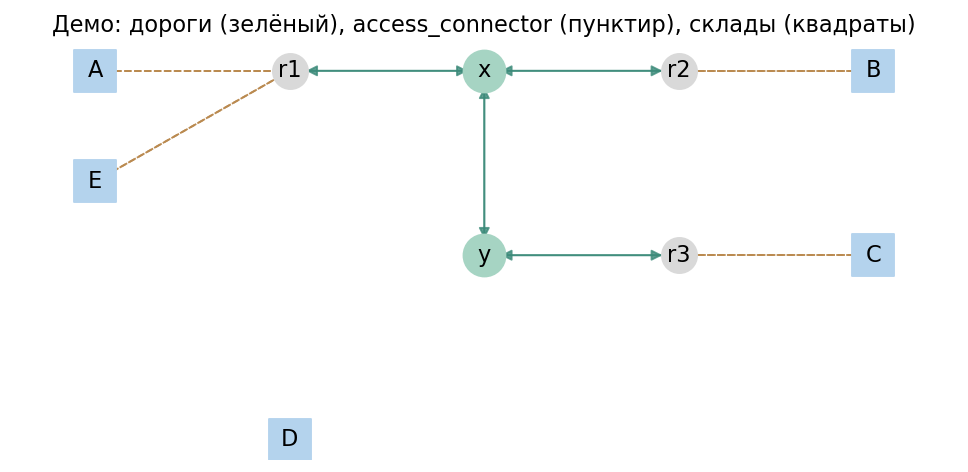

In [4]:
def make_result_graph(base, snap, routes):
    G=nx.MultiDiGraph()
    for w,a in snap.items():
        G.add_node(w,object_type='warehouse',pos={'A':(-1,1),'B':(3,1),'C':(3,0),
                                                  'D':(0,-1),'E':(-1,0.4)}[w])
    used_pairs=set()
    for r in routes:
        if r['status']=='found':
            used_pairs.update(zip(r['node_path'][:-1],r['node_path'][1:]))
    for u,v in used_pairs:
        key,data=min(base[u][v].items(),key=lambda item:item[1]['length_m'])
        for node in (u,v):
            if node not in G:
                G.add_node(node,**base.nodes[node])
        G.add_edge(u,v,key=key,**dict(data))
    connected={r['origin_id'] for r in routes if r['status']=='found'} |               {r['destination_id'] for r in routes if r['status']=='found'}
    for w in connected:
        a=snap[w]
        if a not in G: G.add_node(a,**base.nodes[a])
        G.add_edge(w,a,key='out',edge_type='access_connector',length_m=25.0)
        G.add_edge(a,w,key='in',edge_type='access_connector',length_m=25.0)
    G.graph['routes']=routes
    return G

G=make_result_graph(BASE,SNAP,ROUTES)
pos=nx.get_node_attributes(G,'pos')
plt.figure(figsize=(9,4))
road_edges=[(u,v) for u,v,d in G.edges(data=True) if d.get('edge_type')=='road']
conn_edges=[(u,v) for u,v,d in G.edges(data=True) if d.get('edge_type')=='access_connector']
nx.draw_networkx_nodes(G,pos,nodelist=[n for n,d in G.nodes(data=True) if d['object_type']=='warehouse'],node_shape='s',node_color='#b4d3ed',node_size=520)
nx.draw_networkx_nodes(G,pos,nodelist=[n for n,d in G.nodes(data=True) if d['object_type']=='intersection'],node_color='#a6d4c3',node_size=500)
nx.draw_networkx_nodes(G,pos,nodelist=[n for n,d in G.nodes(data=True) if d['object_type']=='road_node'],node_color='#d9d9d9',node_size=350)
nx.draw_networkx_edges(G,pos,edgelist=road_edges,arrows=True,edge_color='#3b8a79',alpha=.8,arrowsize=12)
nx.draw_networkx_edges(G,pos,edgelist=conn_edges,style='dashed',edge_color='#ba8a50',arrows=False)
nx.draw_networkx_labels(G,pos)
plt.title('Демо: дороги (зелёный), access_connector (пунктир), склады (квадраты)')
plt.axis('off')
show_plot()

## 2. Общие метрики графа

Для физического количества дорог нужна дедупликация по `segment_id`, а не по парам узлов. Для слабых компонент считаем весь итоговый граф **со складами и служебными связями**, временно забыв направление движения. Это не гарантирует направленной достижимости между всеми складами.

В **текущем** коде `get_route_road_graph_summary()` под `road_segments_count` пока суммируются **направленные** дорожные рёбра.

In [5]:
WAREHOUSE_TYPES={'warehouse','facility','terminal','port'}
def graph_summary(g, routes):
    types=Counter(d.get('object_type') for _,d in g.nodes(data=True))
    warehouse_ids={n for n,d in g.nodes(data=True) if d.get('object_type') in WAREHOUSE_TYPES}
    segments={d.get('segment_id') for _,_,d in g.edges(data=True) if d.get('edge_type')=='road'}
    assert None not in segments, 'segment_id обязателен для дорожного участка'
    connected_warehouses={r['origin_id'] for r in routes if r['status']=='found'} |                          {r['destination_id'] for r in routes if r['status']=='found'}
    return {
        'node_count': g.number_of_nodes(),
        'warehouse_count': len(warehouse_ids),
        'intersection_count': types['intersection'],
        'road_node_count': types['road_node'],
        'road_segment_count':len(segments),
        'directed_road_edge_count':sum(d.get('edge_type')=='road' for _,_,d in g.edges(data=True)),
        'access_connector_count':sum(d.get('edge_type')=='access_connector' for _,_,d in g.edges(data=True)),
        'component_count':nx.number_weakly_connected_components(g),
        'warehouses_without_routes_count': len(warehouse_ids-connected_warehouses),
        'total_routes_count':len(routes),
        'found_routes_count':sum(r['status']=='found' for r in routes),
    }

summary=graph_summary(G,ROUTES)
pd.Series(summary).to_frame('Значение')

,Значение
node_count,10
warehouse_count,5
intersection_count,2
road_node_count,3
road_segment_count,4
directed_road_edge_count,8
access_connector_count,8
component_count,2
warehouses_without_routes_count,1
total_routes_count,20


In [6]:
assert summary['node_count']==10
assert summary['warehouse_count']==5
assert summary['intersection_count']==2
assert summary['road_node_count']==3
assert summary['road_segment_count']==4
assert summary['directed_road_edge_count']==8
assert summary['component_count']==2
assert summary['warehouses_without_routes_count']==1
assert summary['found_routes_count']==12

# Отдельная проверка: параллельная дорога — другой segment_id при той же паре узлов.
parallel=G.copy()
parallel.add_edge('r1','x',key='parallel',edge_type='road',length_m=520,segment_id='parallel')
parallel.add_edge('x','r1',key='parallel',edge_type='road',length_m=520,segment_id='parallel')
assert graph_summary(parallel,ROUTES)['road_segment_count']==5
print('Тесты подсчёта вершин, компонентов, сегментов и параллельных дорог пройдены')

Тесты подсчёта вершин, компонентов, сегментов и параллельных дорог пройдены


## 3. Почему старые метрики склада не берём в обязательный MVP

- Если все склады взаимно достижимы, `reachable_count = N-1` и одинаков для каждого склада.
- При полной достижимости и длинах в **км** формула старого `weighted_closeness` из #28 превращается в `1 / average_distance_km`. Показывать их одновременно — почти дублирование.
- Средняя дистанция до всех остальных складов зависит от **размера и формы выбранного региона**, распределения объектов и границ области. Это не оценка фактического подъезда к конкретному складу.

Это **не означает**, что метрики математически неправильны: их можно оставить для исследовательского сравнения, но не передавать как ключевые показатели карточки склада.

In [7]:
# Пример без повторного перебора 500x499 маршрутов: тождество при полной достижимости.
for mean_km in (4.0, 8.0, 15.0):
    N=500
    R=N-1
    distances_sum_km=R*mean_km
    weighted_closeness=(R/distances_sum_km)*(R/(N-1))
    assert abs(weighted_closeness-1/mean_km)<1e-12
    print(f'Средняя дистанция {mean_km:4.1f} км => Weighted Closeness {weighted_closeness:.4f} км⁻¹')

Средняя дистанция  4.0 км => Weighted Closeness 0.2500 км⁻¹
Средняя дистанция  8.0 км => Weighted Closeness 0.1250 км⁻¹
Средняя дистанция 15.0 км => Weighted Closeness 0.0667 км⁻¹


## 4. Новые метрики складов

Пусть `N` — число отобранных складов, `d(w,j)` — длина дорожной части сохранённого **направленного** маршрута из склада `w` в склад `j`. Используем записи `graph.graph['routes']`: `origin_id`, `destination_id`, `status`, `road_length_m`. В текущей реализации маршрут выбирается по полному приближённому расстоянию (дорога + служебные плечи); поэтому `road_length_m` — дорожная часть **выбранного** маршрута, не обязательно глобальный минимум только по дорогам среди всех возможных точек привязки.

- `nearest_warehouse_distance_m(w) = min d(w,j)` по найденным маршрутам к другим складам.
- `nearby_warehouse_count(w;R) = |{j != w: status(w,j) = found и d(w,j) <= R}|`.

Порог включителен. Сам склад исключаем; считаем уникальные `destination_id`. A→B и B→A не взаимозаменяемы. Новая маршрутизация и классификация `highway` не нужны. `access_connector` не добавляем по прежнему решению: его длина — приблизительная геометрическая привязка. Сравнение с `total_length_m` оставляем только в исследовании.

Для отсутствия найденных исходящих маршрутов: ближайшее расстояние не определено (`None` / нет записи), число соседних складов = 0 **если проверены все пары**. При неполном наборе направлений (например, kNN) нельзя выдавать частичные результаты за полные. В прототипе возвращаем отсутствие обоих показателей для такого склада. Если два разных склада имеют одну точку привязки, длина 0 допустима: не заменять произвольным эпсилоном. Это длина по дорогам, а не расстояние между зданиями.

In [8]:
def calculate_warehouse_metrics(warehouse_ids, routes, radii_m=(2000,), distance_key='road_length_m'):
    """Один проход по направленным записям; повторный поиск пути не нужен."""
    ids = list(dict.fromkeys(map(str, warehouse_ids)))
    id_set = set(ids)
    radii = tuple(sorted(set(radii_m)))
    if not radii or any(not math.isfinite(r) or r < 0 for r in radii):
        raise ValueError('Некорректный радиус')
    rows = {w: {'min_m': None, 'nearest_id': None, 'checked_count': 0,
                'found_count': 0, 'counts': {r: 0 for r in radii}} for w in ids}
    seen = set()
    for route in routes:
        a, b = str(route['origin_id']), str(route['destination_id'])
        if a == b:
            continue
        if a not in id_set or b not in id_set:
            raise ValueError(f'Маршрут содержит неизвестный склад: {a} → {b}')
        pair = (a, b)
        if pair in seen:
            raise ValueError(f'Повтор записи для направленной пары: {pair}')
        seen.add(pair)
        status = route.get('status')
        row = rows[a]
        if status == 'not_found_in_data':
            row['checked_count'] += 1
            continue
        if status != 'found':
            # not_checked и неизвестные статусы не считаются проверенными
            continue
        row['checked_count'] += 1
        d = route.get(distance_key)
        if d is None or not math.isfinite(float(d)) or float(d) < 0:
            raise ValueError(f'Некорректная длина маршрута {a} → {b}: {d}')
        d = float(d)
        row['found_count'] += 1
        if row['min_m'] is None or (d, b) < (row['min_m'], row['nearest_id']):
            row['min_m'], row['nearest_id'] = d, b
        for r in radii:
            row['counts'][r] += int(d <= r)
    result = []
    for w, row in rows.items():
        complete = row['checked_count'] == len(ids) - 1
        result.append({'node_id': w, 'complete': complete,
                       'checked_count': row['checked_count'], 'found_count': row['found_count'],
                       'nearest_id': row['nearest_id'] if complete else None,
                       'nearest_warehouse_distance_m': row['min_m'] if complete else None,
                       **{f'nearby_{r}_m': row['counts'][r] if complete else None for r in radii}})
    columns = ['node_id', 'complete', 'checked_count', 'found_count', 'nearest_id',
               'nearest_warehouse_distance_m'] + [f'nearby_{r}_m' for r in radii]
    return pd.DataFrame(result, columns=columns).set_index('node_id')

control = calculate_warehouse_metrics(SNAP, ROUTES, (900, 2000))
display(control)

,complete,checked_count,found_count,nearest_id,nearest_warehouse_distance_m,nearby_900_m,nearby_2000_m
node_id,,,,,,,
A,True,4,3,E,0.0,2,3
B,True,4,3,A,900.0,2,3
C,True,4,3,B,1300.0,0,3
D,True,4,0,None,NaN,0,0
E,True,4,3,A,0.0,2,3


In [9]:
# Проверяем крайние случаи: общая точка привязки, изолированный склад, точная граница R.
assert control.loc['A', 'nearest_warehouse_distance_m'] == 0
assert control.loc['D', 'nearby_900_m'] == 0
assert pd.isna(control.loc['D', 'nearest_warehouse_distance_m'])
assert control.loc['A', 'nearby_900_m'] == 2  # E=0, B=900
one_way = [dict(origin_id='a', destination_id='b', status='found', road_length_m=1000),
           dict(origin_id='b', destination_id='a', status='not_found_in_data')]
t = calculate_warehouse_metrics(['a','b'], one_way, (1000,))
assert t.loc['a', 'nearby_1000_m'] == 1 and t.loc['b', 'nearby_1000_m'] == 0
assert pd.isna(t.loc['b', 'nearest_warehouse_distance_m'])
incomplete = calculate_warehouse_metrics(['a','b'], one_way[:1], (1000,))
assert not incomplete.loc['b', 'complete'] and pd.isna(incomplete.loc['b','nearby_1000_m'])
single = calculate_warehouse_metrics(['a'], [], (1000,))
assert single.loc['a','nearby_1000_m'] == 0 and pd.isna(single.loc['a','nearest_warehouse_distance_m'])
assert len(calculate_warehouse_metrics([], [], (1000,))) == 0
try:
    calculate_warehouse_metrics(['a','b'], one_way + one_way[:1], (1000,))
except ValueError:
    pass
else:
    raise AssertionError('Дубликат не обнаружен')
print('Проверки односторонности, порога, нулей, отсутствия маршрута, неполного покрытия и дубликатов пройдены.')

Проверки односторонности, порога, нулей, отсутствия маршрута, неполного покрытия и дубликатов пройдены.


## 5. Шушары: исследование на сохранённых данных проекта

**Источник:** `frontend/public/shushary_logistics.geojson`, ветка `feature/road-graph-map`, Git blob SHA `e1de992115bd97b1c0883aeb1db585f931fc60c8`. В исходном GeoJSON 6 точек `logistics_hub`, 30 `transport_route`, 16 `access_connector`. Из маршрутов извлечены поля `source_id`, `target_id`, `road_distance_m`, `total_distance_m`, `snap_origin_m`, `snap_dest_m`; в таблице сокращён префикс `hub_shushary_`. Записи `transport_route` в архиве соответствуют найденным путям.

Таблица встроена для воспроизводимого запуска без сети. Все 6 объектов — **демонстрационные логистические точки прежней модели** (включая терминалы и распределительные центры), не автоматически выбранные склады по актуальным правилам #64. Не используем их для утверждения глобального порога R или фактической грузовой доступности.

In [10]:
archive_csv = """origin,destination,road_length_m,total_length_m,snap_origin_m,snap_dest_m
armada,lenta,1954.8,3329.9,1349.1,26.1
lenta,armada,1954.8,3329.9,26.1,1349.1
armada,pyaterochka,450.2,1961.2,1349.1,161.9
pyaterochka,armada,450.2,1961.2,161.9,1349.1
armada,eurosib,3118.3,4863.6,1349.1,396.1
eurosib,armada,3113.7,4858.9,396.1,1349.1
armada,energo,586.5,2369.8,1349.1,434.2
energo,armada,605.9,2389.2,434.2,1349.1
armada,nordway,7.3,604.4,215.5,381.5
nordway,armada,7.3,614.9,388.2,219.4
lenta,pyaterochka,773.2,1625.9,26.1,826.7
pyaterochka,lenta,773.2,1625.9,826.7,26.1
lenta,eurosib,1136.4,1579.2,46.7,396.1
eurosib,lenta,1114.3,1557.1,396.1,46.7
lenta,energo,2541.2,3001.5,26.1,434.2
energo,lenta,2560.6,3020.9,434.2,26.1
lenta,nordway,1963.8,2893.4,26.1,903.5
nordway,lenta,1963.8,2893.4,903.5,26.1
pyaterochka,eurosib,1936.8,3159.6,826.7,396.1
eurosib,pyaterochka,1932.1,3154.9,396.1,826.7
pyaterochka,energo,586.5,1395.2,374.5,434.2
energo,pyaterochka,605.9,1414.6,434.2,374.5
pyaterochka,nordway,9,1287,374.5,903.5
nordway,pyaterochka,9,1287,903.5,374.5
eurosib,energo,3700.2,4530.5,396.1,434.2
energo,eurosib,3724.2,4554.6,434.2,396.1
eurosib,nordway,3122.7,4422.4,396.1,903.5
nordway,eurosib,3127.4,4427,903.5,396.1
energo,nordway,73.2,1217.9,434.2,710.4
nordway,energo,64.6,1209.3,710.4,434.2"""
arch = pd.read_csv(StringIO(archive_csv))
NAMES = {'armada':'Армада парк', 'lenta':'Лента', 'pyaterochka':'Пятёрочка',
         'eurosib':'Евросиб', 'energo':'Энерго', 'nordway':'Nordway'}
archive_routes = arch.rename(columns={'origin':'origin_id','destination':'destination_id'}).assign(status='found').to_dict('records')
assert len(arch) == len(NAMES)*(len(NAMES)-1) == 30
assert len(arch[['origin','destination']].drop_duplicates()) == 30
assert set(arch.origin) == set(arch.destination) == set(NAMES)
assert np.allclose(arch.road_length_m + arch.snap_origin_m + arch.snap_dest_m,
                   arch.total_length_m, atol=0.11, rtol=0)
archive_result = calculate_warehouse_metrics(NAMES, archive_routes, RADII_M)
assert archive_result.complete.all()
archive_display = archive_result.rename(index=NAMES).copy()
archive_display['nearest_id'] = archive_display.nearest_id.map(NAMES)
cols = ['nearest_id','nearest_warehouse_distance_m']+[f'nearby_{r}_m' for r in RADII_M]
display(archive_display[cols].rename(columns={'nearest_id':'Ближайший объект','nearest_warehouse_distance_m':'Расстояние, м', **{f'nearby_{r}_m':f'До {r/1000:g} км' for r in RADII_M}}))
arch.to_csv(OUT/'shushary_archived_routes.csv', index=False)
archive_result.to_csv(OUT/'shushary_archived_metrics.csv')

,Ближайший объект,"Расстояние, м",До 1 км,До 2 км,До 3 км,До 5 км,До 10 км
node_id,,,,,,,
Армада парк,Nordway,7.3,3,4,4,5,5
Лента,Пятёрочка,773.2,1,4,5,5,5
Пятёрочка,Nordway,9.0,4,5,5,5,5
Евросиб,Лента,1114.3,0,2,2,5,5
Энерго,Nordway,73.2,3,3,4,5,5
Nordway,Армада парк,7.3,3,4,4,5,5


,"Радиус, км",Мин. соседей,Макс. соседей,Разных значений,Складов с 0 соседей,Складов со всеми соседями
0,1.0,0,4,4,1,0
1,2.0,2,5,4,0,1
2,3.0,2,5,3,0,2
3,5.0,5,5,1,0,6
4,10.0,5,5,1,0,6


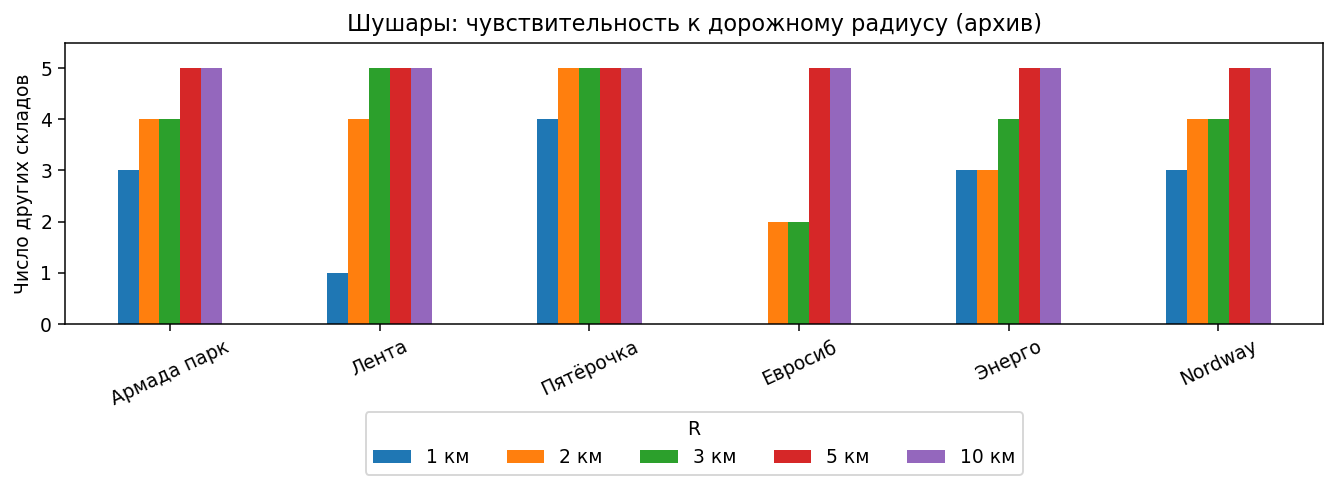

In [11]:
# Сравнение радиусов: доля насыщения — сколько складов видят все остальные.
radius_summary = pd.DataFrame([{'Радиус, км':r/1000,
                                 'Мин. соседей':int(archive_result[f'nearby_{r}_m'].min()),
                                 'Макс. соседей':int(archive_result[f'nearby_{r}_m'].max()),
                                 'Разных значений':int(archive_result[f'nearby_{r}_m'].nunique()),
                                 'Складов с 0 соседей':int((archive_result[f'nearby_{r}_m']==0).sum()),
                                 'Складов со всеми соседями':int((archive_result[f'nearby_{r}_m']==len(NAMES)-1).sum())}
                                for r in RADII_M])
display(radius_summary)
counts = archive_result[[f'nearby_{r}_m' for r in RADII_M]].rename(index=NAMES)
counts.columns = [f'{r/1000:g} км' for r in RADII_M]
ax = counts.plot(kind='bar', figsize=(10,4), rot=25)
ax.set_ylabel('Число других складов'); ax.set_xlabel(''); ax.set_title('Шушары: чувствительность к дорожному радиусу (архив)')
ax.legend(title='R', ncol=5, loc='upper center', bbox_to_anchor=(.5,-.28))
ax.set_ylim(0,5.5); plt.tight_layout(); show_plot()

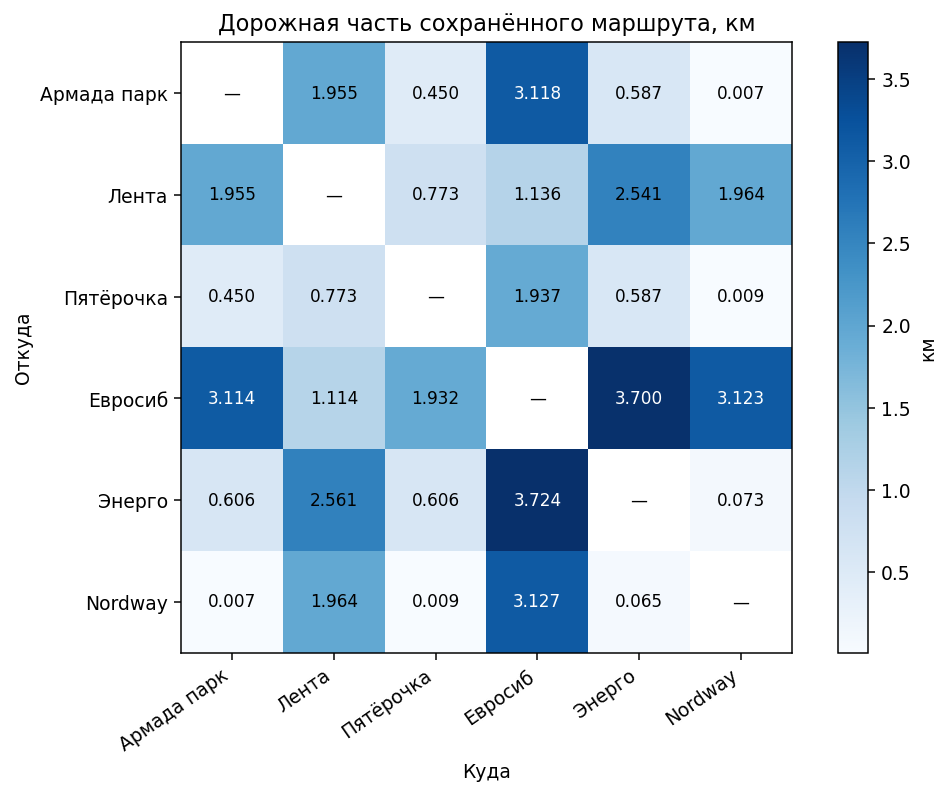

In [12]:
# Матрица длин дорожной части: строки — отправление, столбцы — назначение.
matrix = arch.pivot(index='origin',columns='destination',values='road_length_m').reindex(index=NAMES, columns=NAMES)
fig, ax = plt.subplots(figsize=(8,6))
im = ax.imshow(matrix.to_numpy()/1000, cmap='Blues')
ax.set_xticks(range(len(NAMES)), list(NAMES.values()), rotation=35, ha='right')
ax.set_yticks(range(len(NAMES)), list(NAMES.values()))
ax.set_xlabel('Куда'); ax.set_ylabel('Откуда'); ax.set_title('Дорожная часть сохранённого маршрута, км')
for i in range(len(NAMES)):
    for j in range(len(NAMES)):
        v=matrix.iloc[i,j]
        ax.text(j,i,'—' if pd.isna(v) else f'{v/1000:.3f}', ha='center', va='center', color='white' if v>2600 else 'black',fontsize=9)
fig.colorbar(im,ax=ax,label='км'); fig.tight_layout(); show_plot()

In [13]:
# Чувствительность к приблизительным служебным подключениям.
full_result = calculate_warehouse_metrics(NAMES, archive_routes, RADII_M, distance_key='total_length_m')
comparison = pd.DataFrame({
    'Ближайший (дороги), м':archive_result.nearest_warehouse_distance_m,
    'Ближайший (полная оценка), м':full_result.nearest_warehouse_distance_m,
    'Соседи 2 км (дороги)':archive_result['nearby_2000_m'],
    'Соседи 2 км (полная оценка)':full_result['nearby_2000_m'],
    'Ближайший объект изменился':archive_result.nearest_id != full_result.nearest_id,
}).rename(index=NAMES)
display(comparison)
long_connectors = ((arch.snap_origin_m>250)|(arch.snap_dest_m>250)).sum()
print(f'Маршрутов, где хотя бы одно плечо >250 м: {long_connectors}/{len(arch)}')
print('Максимальное служебное плечо, м:',max(arch.snap_origin_m.max(),arch.snap_dest_m.max()))
comparison.to_csv(OUT/'shushary_distance_sensitivity.csv')

,"Ближайший (дороги), м","Ближайший (полная оценка), м",Соседи 2 км (дороги),Соседи 2 км (полная оценка),Ближайший объект изменился
node_id,,,,,
Армада парк,7.3,604.4,4,2,False
Лента,773.2,1579.2,4,2,True
Пятёрочка,9.0,1287.0,5,4,False
Евросиб,1114.3,1557.1,2,1,False
Энерго,73.2,1217.9,3,2,False
Nordway,7.3,614.9,4,3,False


Маршрутов, где хотя бы одно плечо >250 м: 30/30
Максимальное служебное плечо, м: 1349.1


### Вывод по архиву

- В дорожном радиусе 1 км соседей 0–4, в 2 км — 2–5, в 3 км — 2–5. В радиусах 5 и 10 км все 6 объектов имеют одинаковое значение 5. Порог 2 км — **рабочий кандидат**, не универсальная норма. Для большей территории нужен повторный эксперимент.
- Ближайшие дорожные расстояния лежат в диапазоне 7,3–1114,3 м. Для Армады и Nordway получено 7,3 м; это длина дорожного участка между точками подключения, а не расстояние между зданиями. Старые служебные подключения иногда очень длинные: у всех 30 маршрутов хотя бы одно плечо >250 м, максимум 1349,1 м. При включении полной длины меняется в том числе ближайший объект для Ленты. Эти числа подтверждают чувствительность к привязке и **не подтверждают** реальную доступность.
- Обе метрики можно считать без повторного обращения к OSM. Они описывают локальное расположение логистических объектов по сети, не качество самой дорожной инфраструктуры, не время поездки, не фактический спрос или резерв мощности.
- Границы выбранной области влияют на число соседей. Считать только другие **отобранные склады региона**; не сравнивать регионы с разными R, отбором или правилами привязки без оговорок.

In [14]:
# Оценка затрат на агрегацию уже найденных путей, без маршрутизации.
from random import Random
rng = Random(42)
ids = [str(i) for i in range(500)]
mock_routes = [dict(origin_id=a,destination_id=b,status='found',road_length_m=rng.randint(0,15000))
               for a in ids for b in ids if a!=b]
t0=time.perf_counter()
mock_metrics=calculate_warehouse_metrics(ids,mock_routes,(R_M,))
elapsed=time.perf_counter()-t0
assert len(mock_metrics)==500 and mock_metrics.complete.all()
print(f'Синтетика: {len(mock_routes):,} направлений; агрегация: {elapsed:.3f} с')
print('Это замер только агрегации, без построения OSM-графа и поиска путей.')
del mock_routes, mock_metrics

Синтетика: 249,500 направлений; агрегация: 0.458 с
Это замер только агрегации, без построения OSM-графа и поиска путей.


## 6. Метрики перекрёстков

Для первых двух метрик строим направленный дорожный подграф итогового графа: включаем `intersection` и `road_node`, исключаем склады и `access_connector`. Результат сохраняем только для перекрёстков. Параллельные рёбра одной направленной пары сворачиваем, оставляя минимальную положительную длину.

### 6.1. Определения и контрольный расчёт

- **PageRank** (`pagerank`): структурная значимость узла через входящие связи. Используем `alpha=0.85`, `weight=None`, без весов по длине. Сумма значений всех дорожных узлов равна 1, не только перекрёстков.
- **Betweenness Centrality** (`betweenness_centrality`): доля кратчайших направленных путей между всеми дорожными вершинами, проходящих через узел (не считая концов пути). Если есть несколько равноценных кратчайших путей, вклад делится между ними. Недостижимые пары не вносят вклад. Нормировка — по всем возможным упорядоченным парам других дорожных узлов. Для весов используем положительные длины в целых сантиметрах.
- **Доля складских маршрутов** (`route_fraction`): $M_v/M$, где $M$ — число найденных направленных маршрутов склад→склад, $M_v$ — число таких сохранённых маршрутов, чей `node_path` содержит перекрёсток v. Учитываем одно посещение на маршрут, включая дорожные точки привязки, если они входят в путь. При отсутствии маршрутов или некорректных данных путей значение не определено.

Центральности описывают подграф использованных дорог, а не все дороги региона. Ни одна метрика не измеряет реальный грузопоток. Постановка betweenness между всеми дорожными вершинами — рабочий вариант, не отдельное подтверждённое решение заказчика.


In [15]:
def simple_road_digraph(g):
    road_nodes=[n for n,d in g.nodes(data=True) if d.get('object_type') in ('intersection','road_node')]
    H=nx.DiGraph()
    H.add_nodes_from((n,g.nodes[n].copy()) for n in road_nodes)
    for u,v,d in g.edges(data=True):
        if d.get('edge_type')!='road' or u not in H or v not in H: continue
        x=float(d.get('length_m',float('nan')))
        if not math.isfinite(x) or x<=0:
            raise ValueError(f'Плохая длина road: {u}->{v}, {x}')
        weight_cm=max(1,round(x*100))
        if not H.has_edge(u,v) or weight_cm<H[u][v]['weight_cm']:
            H.add_edge(u,v,weight_cm=weight_cm)
    return H

H=simple_road_digraph(G)
pr=nx.pagerank(H,alpha=.85,weight=None)
bet=nx.betweenness_centrality(H,normalized=True,weight='weight_cm',endpoints=False)
ix=[n for n,d in H.nodes(data=True) if d.get('object_type')=='intersection']
pd.DataFrame({'PageRank':{x:pr[x] for x in ix},'Betweenness':{x:bet[x] for x in ix}}).round(6)

,PageRank,Betweenness
x,0.357557,0.833333
y,0.245493,0.500000


In [16]:
def intersection_route_fraction(g, routes):
    ix = [n for n,d in g.nodes(data=True) if d.get('object_type')=='intersection']
    ix_by_id = {str(v):v for v in ix}
    road_nodes = {str(n) for n,d in g.nodes(data=True)
                  if d.get('object_type') in ('intersection','road_node')}
    found = [r for r in routes if r.get('status')=='found']
    if not found:
        return {v:None for v in ix}
    visits = Counter()
    for r in found:
        path = r.get('node_path')
        if not isinstance(path, (list,tuple)) or not path:
            return {v:None for v in ix}
        path_ids = set(map(str,path))
        if not path_ids <= road_nodes:
            return {v:None for v in ix}
        visits.update(path_ids & ix_by_id.keys())
    return {v:visits[str(v)]/len(found) for v in ix}

shares=intersection_route_fraction(G,ROUTES)
pd.DataFrame({'PageRank':{x:pr[x] for x in ix},
              'Betweenness':{x:bet[x] for x in ix},
              'Route fraction':shares}).round(6)

,PageRank,Betweenness,Route fraction
x,0.357557,0.833333,0.833333
y,0.245493,0.500000,0.500000


In [17]:
assert shares['x']==10/12
assert shares['y']==6/12
assert all(0<=v<=1 for v in shares.values())
assert intersection_route_fraction(G,[] )=={'x':None,'y':None}
print('Доли маршрутов и отсутствие маршрутов проверены')

Доли маршрутов и отсутствие маршрутов проверены


### 6.2. Чем различаются три метрики

На первом контрольном графе betweenness и доля маршрутов случайно совпали. Это не тождество. Проверим двустороннюю цепочку из пяти дорожных вершин, склады A и B подключены к её концам. Для простоты X, Y, Z помечены как условные перекрёстки (не пример классификации OSM). Через них проходят оба складских маршрута, но доля всех кратчайших дорожных путей различается.

,pagerank,betweenness_centrality,route_fraction
node_id,,,
X,0.245945,0.500000,1.0
Y,0.239055,0.666667,1.0
Z,0.245945,0.500000,1.0


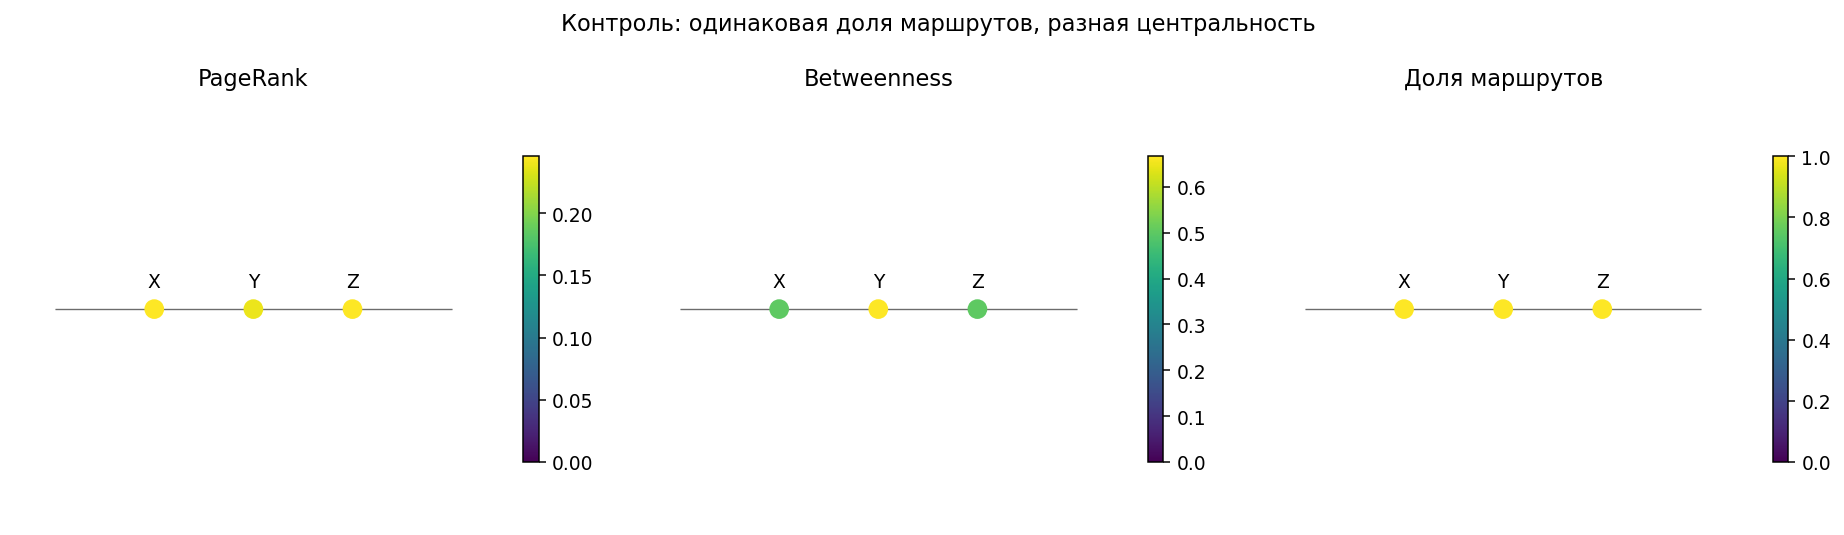

In [18]:
def calculate_intersection_metrics(graph, routes, exact_limit=1000, sample_k=64):
    H = simple_road_digraph(graph)
    n = H.number_of_nodes()
    ix = [v for v,d in H.nodes(data=True) if d.get('object_type')=='intersection']
    columns = ['pagerank','betweenness_centrality','route_fraction']
    if not ix:
        return pd.DataFrame(columns=columns).rename_axis('node_id'), 'нет перекрёстков'
    pr = nx.pagerank(H, alpha=.85, weight=None)
    k = min(sample_k,n) if n > exact_limit else None
    bc = nx.betweenness_centrality(H, k=k, normalized=True, weight='weight_cm',
                                  endpoints=False, seed=42)
    shares = intersection_route_fraction(graph, routes)
    result = pd.DataFrame({'pagerank':{v:pr[v] for v in ix},
                           'betweenness_centrality':{v:bc[v] for v in ix},
                           'route_fraction':shares}).rename_axis('node_id')
    return result, ('точный' if k is None else f'приближённый, k={k}')

# Три схемы: цвет кружка соответствует значению метрики.
def plot_intersection_metrics(graph, metrics, positions=None, title='Перекрёстки'):
    if metrics.empty:
        print('Нет перекрёстков для визуализации.')
        return
    H = simple_road_digraph(graph)
    if positions is None:
        attrs = [(v,d.get('x',d.get('longitude')),d.get('y',d.get('latitude')))
                 for v,d in H.nodes(data=True)]
        if not all(x is not None and y is not None for _,x,y in attrs):
            print('Нет координат всех дорожных вершин: схема пропущена.')
            return
        positions = {v:(float(x),float(y)) for v,x,y in attrs}
    fig, axes = plt.subplots(1,3,figsize=(14,4))
    for ax,col,label in zip(axes,metrics.columns,['PageRank','Betweenness','Доля маршрутов']):
        nx.draw_networkx_edges(H,positions,ax=ax,arrows=False,width=.7,alpha=.35)
        good=metrics[col].dropna().astype(float)
        missing=metrics.index.difference(good.index)
        if len(missing):
            ax.scatter([positions[v][0] for v in missing],[positions[v][1] for v in missing],s=22,marker='x')
        if len(good):
            sc=ax.scatter([positions[v][0] for v in good.index],[positions[v][1] for v in good.index],
                          c=good.values,cmap='viridis',s=90 if len(good)<30 else 12,zorder=3,
                          vmin=0, vmax=1 if col=='route_fraction' else max(float(good.max()),1e-12))
            fig.colorbar(sc,ax=ax,shrink=.72)
        if len(metrics)<=10:
            for v in metrics.index:
                ax.annotate(str(v),positions[v],xytext=(0,12),textcoords='offset points',ha='center')
        ax.set_title(label); ax.set_axis_off()
    fig.suptitle(title); fig.tight_layout(); show_plot()

chain=nx.MultiDiGraph()
chain_nodes=['r0','X','Y','Z','r4']
for v in chain_nodes:
    chain.add_node(v,object_type='intersection' if v in ('X','Y','Z') else 'road_node')
for i,(u,v) in enumerate(zip(chain_nodes[:-1],chain_nodes[1:])):
    for a,b in ((u,v),(v,u)):
        chain.add_edge(a,b,edge_type='road',length_m=100,segment_id=f'chain{i}')
for w,v in [('A','r0'),('B','r4')]:
    chain.add_node(w,object_type='warehouse')
    chain.add_edge(w,v,edge_type='access_connector',length_m=20)
    chain.add_edge(v,w,edge_type='access_connector',length_m=20)
chain_routes=[dict(origin_id='A',destination_id='B',status='found',node_path=chain_nodes),
              dict(origin_id='B',destination_id='A',status='found',node_path=chain_nodes[::-1])]
chain_metrics, method = calculate_intersection_metrics(chain,chain_routes)
display(chain_metrics.round(6))
assert chain_metrics['route_fraction'].eq(1).all()
assert abs(chain_metrics.loc['X','betweenness_centrality']-0.5)<1e-9
assert abs(chain_metrics.loc['Y','betweenness_centrality']-2/3)<1e-9
assert intersection_route_fraction(chain,[dict(status='found',node_path=['unknown'])])=={'X':None,'Y':None,'Z':None}
plot_intersection_metrics(chain,chain_metrics,{v:(i,0) for i,v in enumerate(chain_nodes)},
                          'Контроль: одинаковая доля маршрутов, разная центральность')

**Вывод:** X, Y и Z участвуют в 100% сохранённых складских маршрутов, однако Y важнее для кратчайших путей между всеми дорожными вершинами. PageRank даёт самостоятельную структурную оценку. Это разные характеристики.

### 6.3. Небольшая проверка производительности betweenness

Искусственная сеть, поэтому секунды не являются обещанием производительности на реальном OSM.

In [19]:
def synthetic_road(n):
    H=nx.DiGraph()
    H.add_nodes_from(range(n))
    # двусторонняя цепочка плюс редкие перемычки
    for i in range(n-1):
        H.add_edge(i,i+1,weight_cm=10000)
        H.add_edge(i+1,i,weight_cm=10000)
    for i in range(0,n-7,7):
        H.add_edge(i,i+7,weight_cm=50000)
    return H

rows=[]
for n in (80,160,320):
    h=synthetic_road(n)
    t=time.perf_counter(); nx.pagerank(h,weight=None); t_pr=time.perf_counter()-t
    t=time.perf_counter(); nx.betweenness_centrality(h,k=min(32,n),weight='weight_cm',seed=42); t_b_sample=time.perf_counter()-t
    full=None
    if n<=160:
        t=time.perf_counter(); nx.betweenness_centrality(h,weight='weight_cm'); full=time.perf_counter()-t
    rows.append({'V':n,'E':h.number_of_edges(),'PageRank s':round(t_pr,4),
                 'BC k<=32 s':round(t_b_sample,4),'BC exact s':round(full,4) if full is not None else None})
pd.DataFrame(rows)

,V,E,PageRank s,BC k<=32 s,BC exact s
0,80,169,0.0070,0.0091,0.0240
1,160,340,0.0062,0.0173,0.0817
2,320,683,0.0031,0.0356,NaN


## 7. Повтор эксперимента на свежей выгрузке Шушар (опционально)

В этой среде Overpass недоступен (не разрешается имя хоста). Не подменяем свежие данные синтетикой. Чтобы использовать **тот же отбор и привязку**, что в Python-worker, запусти из актуальной версии репозитория (WSL/терминал, уже установленные зависимости проекта):

```bash
cd backend/python
python main.py --bbox 59.795 30.385 59.824 30.441 --osm-pois --osm-limit 100 --max-snap-distance 250 --data-dir data/issue71_shushary --refetch
```

Порядок bbox в CLI: `min_lat min_lon max_lat max_lon`. Это небольшой участок, не все Шушары. **Не добавлять `--knn`**: нужны все направленные пары. 250 м — текущий параметр CLI; отдельно можно повторить с `--max-snap-distance 100` и другой папкой результатов, если команда утвердит 100 м. Если актуальный отбор складов ещё не попал в твою ветку, такой запуск не является проверкой окончательного алгоритма #64/#70. Лимит 100 следует проверить: если он достигнут, повторить с большим лимитом.

Готовый файл `<alias>_route_roads.graphml` содержит `graph.graph['routes']`; его можно загрузить в Colab, либо открыть локально. Установи `FRESH_GRAPHML` ниже на фактический путь. При `None` раздел пропускается, остальные расчёты остаются воспроизводимыми. Данные нового запуска храним отдельно от архива.

Архив Шушар не содержит `node_path`, ID промежуточных дорожных узлов и типов перекрёстков. Нельзя получать их простым пересечением линий на карте: дороги могут пересекаться на разных уровнях. Поэтому центральности Шушар считаются только по свежему итоговому GraphML. Добавлен отдельный CSV по перекрёсткам и три схемы сети.

In [20]:
FRESH_GRAPHML = None  # например, 'data/issue71_shushary/...._route_roads.graphml'

def read_route_graphml(path):
    graph = nx.read_graphml(path, force_multigraph=True)
    if not graph.is_directed():
        raise ValueError('Ожидается направленный итоговый дорожный граф')
    raw = graph.graph.get('routes')
    if raw is None:
        raise ValueError('В GraphML нет сохранённых маршрутов graph.graph["routes"]')
    routes = json.loads(raw) if isinstance(raw,str) else raw
    if not isinstance(routes, list):
        raise ValueError('routes должен быть списком записей')
    ids = [n for n,data in graph.nodes(data=True) if data.get('object_type') in WAREHOUSE_TYPES]
    return graph, ids, routes

# Контроль чтения GraphML в формате backend: routes сериализован JSON-строкой.
from tempfile import TemporaryDirectory
with TemporaryDirectory() as tmp:
    sample_path = Path(tmp)/'control.graphml'
    copy = G.copy()
    copy.graph['routes'] = json.dumps(ROUTES)
    for _,data in copy.nodes(data=True):
        data.pop('pos',None)
    nx.write_graphml(copy, sample_path)
    loaded, sample_ids, sample_routes = read_route_graphml(sample_path)
    assert len(sample_ids)==5 and len(sample_routes)==20
    assert calculate_warehouse_metrics(sample_ids,sample_routes,(900,)).loc['A','nearby_900_m']==2
print('Контроль чтения сохранённых маршрутов из GraphML пройден.')

if FRESH_GRAPHML is None:
    print('Свежие результаты не загружены. Архив Шушар и тесты выше доступны.')
else:
    fresh_graph,fresh_ids,fresh_routes=read_route_graphml(FRESH_GRAPHML)
    fresh_result=calculate_warehouse_metrics(fresh_ids,fresh_routes,RADII_M)
    print('Складов:',len(fresh_ids),'Записей маршрутов:',len(fresh_routes),
          'Полностью проверенных складов:',int(fresh_result.complete.sum()))
    display(fresh_result)
    fresh_result.to_csv(OUT/'shushary_fresh_metrics.csv')
    complete=fresh_result.loc[fresh_result.complete]
    if len(complete):
        display(pd.DataFrame([{'Радиус, км':r/1000,'min':complete[f'nearby_{r}_m'].min(),
                               'median':complete[f'nearby_{r}_m'].median(),'max':complete[f'nearby_{r}_m'].max(),
                               'nunique':complete[f'nearby_{r}_m'].nunique(),
                               'все соседи':(complete[f'nearby_{r}_m']==len(fresh_ids)-1).sum()}
                              for r in RADII_M]))
        display(complete['nearest_warehouse_distance_m'].describe())
        display(graph_summary(fresh_graph,fresh_routes))
    else:
        print('Нет полного покрытия пар: проверь параметры формирования маршрутов.')

# Все три метрики перекрёстков на том же свежем графе (если он загружен).
if FRESH_GRAPHML is not None:
    t = time.perf_counter()
    fresh_intersections, bc_method = calculate_intersection_metrics(fresh_graph,fresh_routes)
    print('Перекрёстков:',len(fresh_intersections),'Betweenness:',bc_method,
          'Время, с:',round(time.perf_counter()-t,3))
    display(fresh_intersections.sort_values('route_fraction',ascending=False).head(20))
    fresh_intersections.to_csv(OUT/'shushary_fresh_intersection_metrics.csv')
    if not fresh_intersections.empty:
        display(fresh_intersections.describe())
        plot_intersection_metrics(fresh_graph,fresh_intersections,title='Шушары: метрики перекрёстков')
else:
    print('Метрики перекрёстков Шушар пока не рассчитаны: необходим свежий итоговый GraphML.')


Контроль чтения сохранённых маршрутов из GraphML пройден.
Свежие результаты не загружены. Архив Шушар и тесты выше доступны.
Метрики перекрёстков Шушар пока не рассчитаны: необходим свежий итоговый GraphML.


## 8. Результат для #71 и передача #72–73

| Где | Метрики MVP |
|---|---|
| Регион | `warehouse_count`, `intersection_count`, `road_segment_count`, `component_count`, технические `node_count`, `road_node_count` |
| Склад | `nearest_warehouse_distance_m`, `nearby_warehouse_count` при общем R; отдельно статус подключения (атрибут) |
| Перекрёсток | `pagerank`, `betweenness_centrality`, `route_fraction` |

Не выводим `reachable_count`, `average_distance_m`, `weighted_closeness`, не включаем дистанцию до «важной дороги» в обязательный MVP. Записи маршрутов уже есть — обе метрики склада вычисляются одним проходом. `nearby_warehouse_count` — целое число, `nearest_warehouse_distance_m` — метры. В API передавать `node_id`. Порог R должен быть известен frontend и одинаков для всех складов анализа: например, согласованный параметр/метрика уровня региона `warehouse_neighbor_radius_m`. **2000 м — предварительная рекомендация для эксперимента**; значение согласовать, а не скрыто зашить.

При `None` и действующем числовом контракте не передавать запись; настоящий 0 передавать как 0. При неполном покрытии пар не выдавать частичные показатели как полные. На фронтенде лучше подписать «До ближайшего склада по дорогам» и «Других складов в пределах R км по дорогам». Нули дорожной длины и проблемы привязки не означают совпадение зданий.

**Статус исследования:** офлайн-тесты, архивные 6 объектов и 30 направлений, синтетический замер 500 складов; свежая выгрузка пока не выполнена. Классы дорог для «важной дороги» и реальные грузовые ограничения оставляем за рамками MVP. Код — исследовательский прототип, не замена production-сервиса.

В v6 добавлены сравнение центральностей, расчёт, CSV и визуализация при наличии свежего GraphML. Для исследовательского прогона: точный betweenness до 1000 дорожных узлов, выше — выборка 64 источников. Это предварительная настройка, не утверждённый production-порог.